## DBSCAN Clustering on Mall Customers Dataset
We will load the dataset, scale the features, find appropriate DBSCAN parameters, and visualize the identified clusters.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# Load dataset
df = pd.read_csv('/content/Mall_Customers.csv')
display(df.head())

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [2]:
# Select features for clustering (e.g., Annual Income and Spending Score)
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features]

# Scale the features since DBSCAN is highly sensitive to distance metrics
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [3]:
# Apply DBSCAN
# eps determines the maximum distance between two samples for one to be considered as in the neighborhood of the other.
# min_samples determines the number of samples in a neighborhood for a point to be considered as a core point.
dbscan = DBSCAN(eps=0.35, min_samples=5)
df['Cluster'] = dbscan.fit_predict(X_scaled)

# Check the cluster distributions (-1 indicates noise/outliers)
print("Cluster value counts:")
print(df['Cluster'].value_counts())

Cluster value counts:
Cluster
 3    88
 4    31
-1    23
 5    23
 0    16
 1    12
 2     7
Name: count, dtype: int64


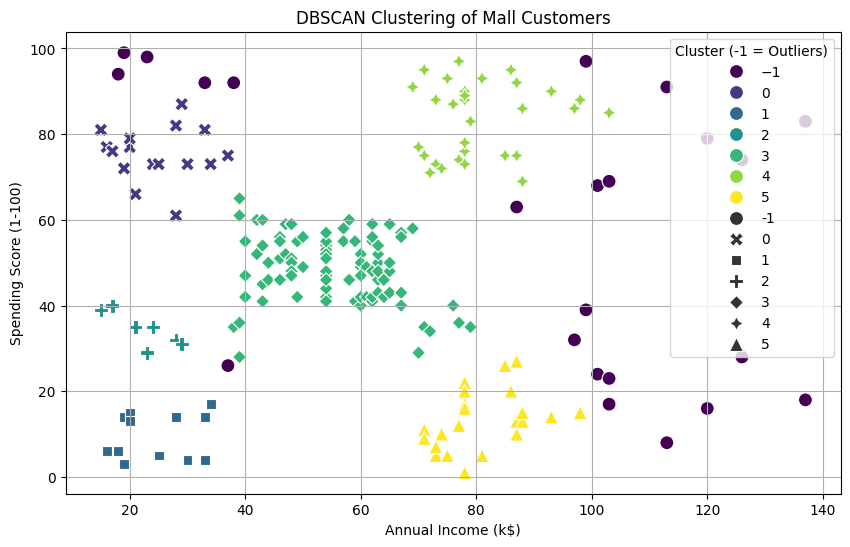

In [4]:
# Visualize the clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=df['Annual Income (k$)'],
    y=df['Spending Score (1-100)'],
    hue=df['Cluster'],
    palette='viridis',
    style=df['Cluster'],
    s=100
)
plt.title('DBSCAN Clustering of Mall Customers')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster (-1 = Outliers)')
plt.grid(True)
plt.show()